#AF7 PIA: Proyecto Final

In [20]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

Parámetros del sistema

In [21]:
m1 = 2.0
m2 = 1.5
l1 = 0.5
lc1 = 0.25
lc2 = 0.20
I1 = 0.05
I2 = 0.03
g = 9.81

Parámetros de fricción

In [22]:
fv1 = 0.14    # Fricción viscosa articulación 1
fv2 = 0.10    # Fricción viscosa articulación 2
fc1 = 0.45    # Fricción de Coulomb articulación 1
fc2 = 0.30    # Fricción de Coulomb articulación 2

Torque aplicado por los motores

In [23]:
def tau(t):
    tau1 = 1.5 * np.sin(t)
    tau2 = 0.5 * np.sin(t)
    return np.array([tau1, tau2])

Modelo dinámico

In [24]:
def f(t, x):
    # Variables de estado
    q1, q2, qp1, qp2 = x

    # Matriz de inercia M(q)
    M11 = m1 * lc1*2 + I1 + I2 + m2 * l12 + m2 * lc2*2 + 2 * m2 * l1 * lc2 * np.cos(q2)
    M12 = I2 + m2 * lc2**2 + m2 * l1 * lc2 * np.cos(q2)
    M21 = M12
    M22 = I2 + m2 * lc2**2
    M = np.array([[M11, M12],
                  [M21, M22]])

    # Vector de Coriolis y centrífuga C(q, qp) * qp
    h_cor = m2 * l1 * lc2 * np.sin(q2)
    C_qp = np.array([
        -h_cor * (2 * qp1 * qp2 + qp2**2),
        h_cor * qp1**2
    ])

    # Vector de gravedad g(q)
    g_vec = np.array([
        (m1 * lc1 + m2 * l1) * g * np.sin(q1) + m2 * lc2 * g * np.sin(q1 + q2),
        m2 * lc2 * g * np.sin(q1 + q2)
    ])

    # Fricción viscosa + Coulomb suavizada
    friccion = np.array([
        fv1 * qp1 + fc1 * np.tanh(100 * qp1),
        fv2 * qp2 + fc2 * np.tanh(100 * qp2)
    ])

    # Ecuación dinámica: M(q)*qpp = tau - C(q,qp)*qp - g(q) - f(qp)
    qpp = np.linalg.solve(M, tau(t) - C_qp - g_vec - friccion)

    # Derivadas de los estados
    dxdt = [qp1, qp2, qpp[0], qpp[1]]
    return dxdt

Parámetros de la simulación

In [25]:
ti = 0.0
tf = 10.0
h = 0.0025

ts = np.linspace(ti, tf, int((tf - ti) / h) + 1)

Condiciones iniciales

In [26]:
q1_0 = 0.0
q2_0 = 0.0
qp1_0 = 0.0
qp2_0 = 0.0

x0 = [q1_0, q2_0, qp1_0, qp2_0]

Resolucion de la ecuación diferencial

In [27]:
# Redefinimos f con las ecuaciones corregidas para solucionar el NameError y los exponentes
def f(t, x):
    # Variables de estado
    q1, q2, qp1, qp2 = x

    # Matriz de inercia M(q) corregida (usando **2 para elevar al cuadrado)
    M11 = m1 * lc1**2 + I1 + I2 + m2 * l1**2 + m2 * lc2**2 + 2 * m2 * l1 * lc2 * np.cos(q2)
    M12 = I2 + m2 * lc2**2 + m2 * l1 * lc2 * np.cos(q2)
    M21 = M12
    M22 = I2 + m2 * lc2**2
    M = np.array([[M11, M12],
                  [M21, M22]])

    # Vector de Coriolis y centrífuga C(q, qp) * qp
    h_cor = m2 * l1 * lc2 * np.sin(q2)
    C_qp = np.array([
        -h_cor * (2 * qp1 * qp2 + qp2**2),
        h_cor * qp1**2
    ])

    # Vector de gravedad g(q)
    g_vec = np.array([
        (m1 * lc1 + m2 * l1) * g * np.sin(q1) + m2 * lc2 * g * np.sin(q1 + q2),
        m2 * lc2 * g * np.sin(q1 + q2)
    ])

    # Fricción viscosa + Coulomb suavizada
    friccion = np.array([
        fv1 * qp1 + fc1 * np.tanh(100 * qp1),
        fv2 * qp2 + fc2 * np.tanh(100 * qp2)
    ])

    # Ecuación dinámica: M(q)*qpp = tau - C(q,qp)*qp - g(q) - f(qp)
    qpp = np.linalg.solve(M, tau(t) - C_qp - g_vec - friccion)

    # Derivadas de los estados
    dxdt = [qp1, qp2, qpp[0], qpp[1]]
    return dxdt

# Ejecución de la integración numérica con la función corregida
sol = solve_ivp(
    f,
    [ti, tf],
    x0,
    t_eval=ts,
    max_step=h,
    rtol=1e-6,
    atol=1e-8
)

if not sol.success:
    raise RuntimeError(sol.message)

Extracción de resultados

In [28]:
t = sol.t
q1 = sol.y[0]
q2 = sol.y[1]
qp1 = sol.y[2]
qp2 = sol.y[3]

Conversión a grados

Simulación completada: 4001 puntos
Posición final: q1 = -2.47°, q2 = 0.49°
Velocidad final: qp1 = -7.09°/s, qp2 = -0.63°/s


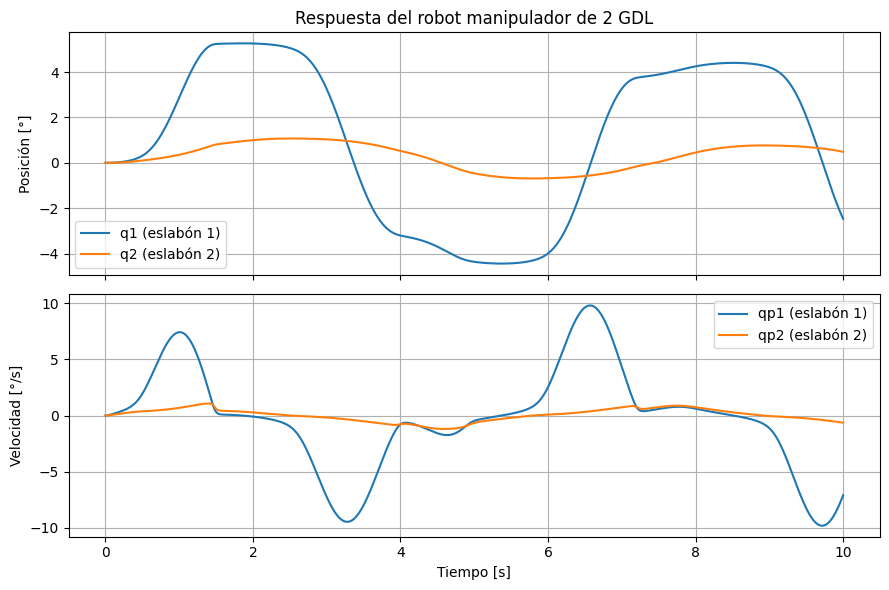

In [29]:
q1_grados = np.rad2deg(q1)
q2_grados = np.rad2deg(q2)
qp1_grados = np.rad2deg(qp1)
qp2_grados = np.rad2deg(qp2)

print(f"Simulación completada: {len(t)} puntos")
print(f"Posición final: q1 = {q1_grados[-1]:.2f}°, q2 = {q2_grados[-1]:.2f}°")
print(f"Velocidad final: qp1 = {qp1_grados[-1]:.2f}°/s, qp2 = {qp2_grados[-1]:.2f}°/s")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax1.plot(t, q1_grados, label='q1 (eslabón 1)')
ax1.plot(t, q2_grados, label='q2 (eslabón 2)')
ax1.set_ylabel('Posición [°]')
ax1.set_title('Respuesta del robot manipulador de 2 GDL')
ax1.grid(True)
ax1.legend()

ax2.plot(t, qp1_grados, label='qp1 (eslabón 1)')
ax2.plot(t, qp2_grados, label='qp2 (eslabón 2)')
ax2.set_xlabel('Tiempo [s]')
ax2.set_ylabel('Velocidad [°/s]')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()